In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from My_Pipeline import my_pipeline

In [2]:
stations_df = pd.read_csv("raw_data/stations.csv", parse_dates=['timestamp'])
weather_df = pd.read_csv("raw_data/weather.csv", parse_dates=['timestamp'])
trips_df = pd.read_csv("raw_data/trips.csv", parse_dates=['started_at', 'ended_at'])

In [3]:
Start_date = pd.Timestamp('2024-09-01 00:00:00+00:00')

In [4]:
stations_df.head(5)

,station,longitude,latitude,timestamp,skipped_updates,free_bikes,free_spots
0,Gågaten,5.318798,60.395070,2024-10-26 13:09:58+00:00,6,7,3
1,Bjørnsonsgate,5.342082,60.373986,2025-03-16 10:23:21+00:00,11,0,19
2,Haukeland sykehus,5.356595,60.373638,2025-04-23 09:36:49+00:00,1,3,16
3,Krohnviken,5.331021,60.378107,2024-10-09 18:24:57+00:00,0,4,15
4,Nykirkekaien,5.314548,60.397057,2024-09-29 09:23:49+00:00,3,3,7


In [5]:
weather_df.head(5)

,timestamp,temperature,precipitation,wind_speed
0,2023-12-31 23:00:00+00:00,3.0,0.0,17.9
1,2024-01-01 00:00:00+00:00,2.8,0.0,13.2
2,2024-01-01 01:00:00+00:00,2.6,0.0,10.5
3,2024-01-01 02:00:00+00:00,2.7,0.0,18.9
4,2024-01-01 03:00:00+00:00,2.1,0.0,18.4


In [6]:
trips_df.head(5)

,started_at,ended_at,start_station_name,start_station_latitude,start_station_longitude,end_station_name,end_station_latitude,end_station_longitude
0,2023-01-01 04:22:50.614000+00:00,2023-01-01 04:33:19.884000+00:00,Torget,60.395878,5.325284,Takhagen på Nordnes,60.398865,5.306411
1,2023-01-01 04:31:33.724000+00:00,2023-01-01 04:33:21.525000+00:00,Kong Oscars gate,60.393323,5.330654,Kong Oscars gate,60.393323,5.330654
2,2023-01-01 04:33:41.500000+00:00,2023-01-01 04:44:24.625000+00:00,Kong Oscars gate,60.393323,5.330654,Skutevikstorget,60.402229,5.320745
3,2023-01-01 05:55:30.388000+00:00,2023-01-01 05:59:17.644000+00:00,John Lunds plass,60.388247,5.324558,Skur 11,60.396384,5.324169
4,2023-01-01 05:59:33.946000+00:00,2023-01-01 06:03:47.999000+00:00,Skur 11,60.396384,5.324169,Hans Hauges gate,60.401906,5.324748


In [7]:
# Konverter til timezone-aware timestamps først (med mixed format for inkonsistente datoer)
stations_df['timestamp'] = pd.to_datetime(stations_df['timestamp'], format='mixed', utc=True)
weather_df['timestamp'] = pd.to_datetime(weather_df['timestamp'], format='mixed', utc=True)
trips_df['started_at'] = pd.to_datetime(trips_df['started_at'], format='mixed', utc=True)

#Deretter filtrer
stations_df = stations_df[stations_df['timestamp'] >= Start_date]
trips_df = trips_df[trips_df['started_at'] >= Start_date]
weather_df = weather_df[weather_df['timestamp'] >= Start_date]

In [8]:
stations_df = stations_df.drop(columns=['longitude', 'latitude', 'free_spots', 'skipped_updates'])

stations_to_predict = [
    'Møllendalsplass', 'Torgallmenningen',
    'Grieghallen', 'Høyteknologisenteret',
    'Studentboligene', 'Akvariet',
    'Damsgårdsveien 71', 'Dreggsallmenningen Sør',
    'Florida Bybanestopp'
]

# Inkluderer kun stasjonene ovenfor
stations_df = stations_df[stations_df["station"].isin(stations_to_predict)]
stations_df["hour"] = stations_df["timestamp"].dt.hour

In [9]:
# Sorter og del inn i 60% treningssett før visualisering
stations_df = stations_df.sort_values("timestamp")
train = int(len(stations_df) * 0.6)

stations_train = stations_df.iloc[:train]
stations_val_test = stations_df.iloc[train:]
train_end_date = stations_train['timestamp'].max()

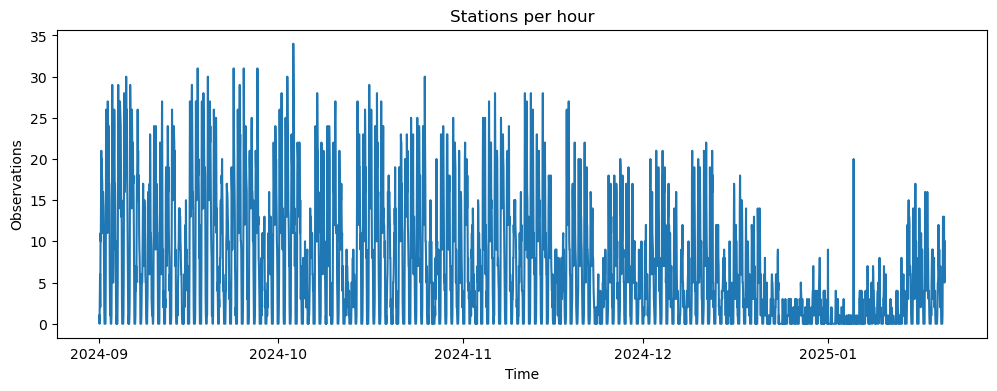

Antall måneder: 5 | Periode: 2024-09-30 → 2025-01-31


In [10]:
# Lag månedskolonne som Period (M) for kompakt gruppering
monthly_avg = (stations_train
               .set_index('timestamp')
               .resample('ME')['free_bikes']
               .mean()
               .to_frame(name='avg_free_bikes'))

stations_hr = stations_train.set_index("timestamp").resample("h").size()
plt.figure(figsize=(12,4))
plt.plot(stations_hr.index, stations_hr.values)
plt.title("Stations per hour")
plt.ylabel("Observations")
plt.xlabel("Time")
plt.show()

print(f"Antall måneder: {len(monthly_avg)} | Periode: {monthly_avg.index.min().date()} → {monthly_avg.index.max().date()}")

In [11]:
# Sjekk tidsperioder for datasettene
print("Stations:")
print(f"  Start: {stations_df['timestamp'].min()}")
print(f"  Slutt: {stations_df['timestamp'].max()}")

print("\nWeather:")
print(f"  Start: {weather_df['timestamp'].min()}")
print(f"  Slutt: {weather_df['timestamp'].max()}")

print("\nTrips:")
print(f"  Start: {trips_df['started_at'].min()}")
print(f"  Slutt: {trips_df['started_at'].max()}")

Stations:
  Start: 2024-09-01 02:43:38+00:00
  Slutt: 2025-05-02 15:49:25+00:00

Weather:
  Start: 2024-09-01 00:00:00+00:00
  Slutt: 2025-05-02 16:00:00+00:00

Trips:
  Start: 2024-09-01 03:37:20.636000+00:00
  Slutt: 2025-05-02 15:52:52.760000+00:00


Sjekke om det mangler data i val og train
gjør om til timer slik at vi kan se hvor mangen rader som mangler

In [12]:
# Sjekk kompletthet per stasjon i val/test
for station in stations_val_test['station'].unique():
    station_data = stations_val_test[stations_val_test['station'] == station].copy()
    station_data = station_data.sort_values('timestamp')
    
    time_diffs = station_data['timestamp'].diff()
    max_gap = time_diffs.max()
    max_gap_hours = max_gap.total_seconds() / 3600 if pd.notna(max_gap) else 0
    
    min_ts, max_ts = station_data['timestamp'].min(), station_data['timestamp'].max()
    expected = int((max_ts - min_ts).total_seconds() / 3600) + 1
    actual = len(station_data)
    pct = (actual / expected) * 100
    
    print(f"{station:30s}: {pct:5.1f}% | Største hull: {max_gap_hours:6.1f}t")

Akvariet                      :  42.5% | Største hull:  127.3t
Høyteknologisenteret          :  67.3% | Største hull:  124.1t
Torgallmenningen              : 107.3% | Største hull:  120.3t
Florida Bybanestopp           :  76.6% | Største hull:  120.3t
Studentboligene               :  68.7% | Største hull:  121.3t
Damsgårdsveien 71             :  90.0% | Største hull:  121.8t
Møllendalsplass               :  86.8% | Største hull:  121.3t
Grieghallen                   :  58.3% | Største hull:  125.3t
Dreggsallmenningen Sør        :  59.7% | Største hull:  120.6t


In [13]:
# Sjekk weather data
weather_sorted = weather_df.sort_values('timestamp')
min_ts, max_ts = weather_sorted['timestamp'].min(), weather_sorted['timestamp'].max()
expected = int((max_ts - min_ts).total_seconds() / 3600) + 1
actual = weather_sorted['timestamp'].nunique()
pct = (actual / expected) * 100

# Finn største gap (i antall timer som mangler, ikke avstand)
time_diffs = weather_sorted['timestamp'].diff()
max_gap_td = time_diffs.max()
max_gap_hours = int(max_gap_td.total_seconds() / 3600) - 1 if pd.notna(max_gap_td) else 0  # -1 for faktisk manglende timer

print(f"\nWeather: {pct:.2f}% | {expected-actual} timer mangler totalt")
print(f"  Største sammenhengende hull: {max_gap_hours} timer mangler på rad")
print(f"  Null-verdier: {weather_df.isnull().sum().to_dict()}")


Weather: 99.98% | 1 timer mangler totalt
  Største sammenhengende hull: 1 timer mangler på rad
  Null-verdier: {'timestamp': 0, 'temperature': 66, 'precipitation': 50, 'wind_speed': 53}


In [14]:
# Sjekk NaN-verdier i stations_df
print("Stations NaN-verdier:")
print(stations_df.isnull().sum())
print(f"\nTotale NaN: {stations_df.isnull().sum().sum()}")

# Sjekk NaN-verdier i trips_df
print("\n" + "="*50)
print("Trips NaN-verdier:")
print(trips_df.isnull().sum())
print(f"\nTotale NaN: {trips_df.isnull().sum().sum()}")

Stations NaN-verdier:
station       0
timestamp     0
free_bikes    0
hour          0
dtype: int64

Totale NaN: 0

Trips NaN-verdier:
started_at                 0
ended_at                   0
start_station_name         0
start_station_latitude     0
start_station_longitude    0
end_station_name           0
end_station_latitude       0
end_station_longitude      0
dtype: int64

Totale NaN: 0


In [15]:
# Sjekk trips data (aggregert per time)
trips_hourly = trips_df.set_index('started_at').resample('h').size()
trips_hourly = trips_hourly[trips_hourly.index >= Start_date]

min_ts, max_ts = trips_hourly.index.min(), trips_hourly.index.max()
expected = int((max_ts - min_ts).total_seconds() / 3600) + 1
actual = len(trips_hourly)
pct = (actual / expected) * 100

# Timer uten turer
zero_trips = (trips_hourly == 0).sum()

print(f"\nTrips: {pct:.1f}% | {expected-actual} timer mangler | {zero_trips} timer med 0 turer")
print(f"  Gjennomsnitt: {trips_hourly.mean():.1f} turer/time | Max: {trips_hourly.max()}")


Trips: 100.0% | 0 timer mangler | 1306 timer med 0 turer
  Gjennomsnitt: 34.7 turer/time | Max: 274


In [16]:
# Heatmap: Ukedag vs time på dagen
stations_train_copy = stations_train.copy()
stations_train_copy['weekday'] = stations_train_copy['timestamp'].dt.day_name()
stations_train_copy['hour'] = stations_train_copy['timestamp'].dt.hour

# Aggreger snitt per ukedag og time
heatmap_data = stations_train_copy.groupby(['weekday', 'hour'])['free_bikes'].mean().reset_index()

# Sorter ukedager riktig (mandag først)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_pivot = heatmap_data.pivot(index='weekday', columns='hour', values='free_bikes')
heatmap_pivot = heatmap_pivot.reindex(weekday_order)

fig = px.imshow(
    heatmap_pivot,
    labels=dict(x="Time på dagen", y="Ukedag", color="Snitt ledige sykler"),
    aspect="auto",
    title="Gjennomsnittlig ledige sykler per ukedag og time",
    color_continuous_scale='RdYlGn'
)
fig.show()

In [17]:
# Heatmap: Antall turer per ukedag og time (kun treningsdata)
trips_train = trips_df[trips_df['started_at'] <= train_end_date].copy()
trips_train['weekday'] = trips_train['started_at'].dt.day_name()
trips_train['hour'] = trips_train['started_at'].dt.hour

# Tell antall turer per ukedag og time
trips_heatmap = trips_train.groupby(['weekday', 'hour']).size().reset_index(name='count')

# Sorter ukedager riktig
trips_pivot = trips_heatmap.pivot(index='weekday', columns='hour', values='count')
trips_pivot = trips_pivot.reindex(weekday_order)

fig = px.imshow(
    trips_pivot,
    labels=dict(x="Time på dagen", y="Ukedag", color="Antall turer"),
    aspect="auto",
    title="Antall turer per ukedag og time (treningsdata)",
    color_continuous_scale='Blues'
)
fig.show()

In [18]:
# Rund ned til time
stations_train['hour_ts'] = stations_train['timestamp'].dt.floor('h')
weather_df['hour_ts'] = weather_df['timestamp'].dt.floor('h')

# Merge på time
data = stations_train.merge(weather_df[['hour_ts', 'temperature', 'precipitation', 'wind_speed']], on='hour_ts')

print(f"\nTemp: {data['temperature'].corr(data['free_bikes']):.3f}")
print(f"Regn: {data['precipitation'].corr(data['free_bikes']):.3f}")
print(f"Vind: {data['wind_speed'].corr(data['free_bikes']):.3f}")


Temp: 0.342
Regn: -0.002
Vind: -0.026


C:\Users\aleks\AppData\Local\Temp\ipykernel_22628\34644715.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [19]:
# Trips vs vær
trips_train = trips_df[trips_df['started_at'] <= train_end_date].copy()
trips_train['hour_ts'] = trips_train['started_at'].dt.floor('h')

# Tell turer per time
trips_hourly = trips_train.groupby('hour_ts').size().reset_index(name='trips_count')

# Merge med weather
trips_weather = trips_hourly.merge(weather_df[['hour_ts', 'temperature', 'precipitation', 'wind_speed']], on='hour_ts')

print(f"\nTrips vs vær:")
print(f"Temp: {trips_weather['temperature'].corr(trips_weather['trips_count']):.3f}")
print(f"Regn: {trips_weather['precipitation'].corr(trips_weather['trips_count']):.3f}")
print(f"Vind: {trips_weather['wind_speed'].corr(trips_weather['trips_count']):.3f}")


Trips vs vær:
Temp: 0.437
Regn: -0.151
Vind: -0.159


In [20]:
model_df = my_pipeline('raw_data')
n = len(model_df)

train_end = int(n * 0.6)
train = model_df.iloc[:train_end]

In [21]:
kolonner = ['free_bikes', 'temperature','precipitation', 'wind_speed', 'flow']
train[kolonner].describe()

,free_bikes,temperature,precipitation,wind_speed,flow
count,22530.000000,22530.000000,22530.000000,22530.000000,22530.000000
mean,7.115313,7.150151,0.348979,11.447932,96.596094
std,7.242134,5.598903,0.760085,7.799257,103.076422
min,0.000000,-12.400000,0.000000,0.000000,0.000000
25%,1.000000,3.600000,0.000000,5.200000,20.000000
50%,5.000000,7.400000,0.000000,9.400000,64.000000
75%,11.000000,10.500000,0.300000,16.275000,137.000000
max,34.000000,27.900000,6.800000,40.600000,556.000000
